### Notebook environment

Select **MAGMA / Glacier (Python 3.10)** in the notebook kernel picker, then restart
the kernel and run the cells again. This registered kernel uses the existing
research environment with MAGMa, RDKit and Glacier dependencies installed.
Switching only to the global Python 3.10 or Python 3.11 interpreter is insufficient.


If even `print()` waits after running the notebook, close the **Jupyter Variables**
panel and interrupt the kernel once. Variable previews can otherwise format the
entire loaded library. The dataset containers and spectrum classes now have
compact previews. Restart the kernel and run from the top once to use these
updated classes; inspect an individual spectrum's `.peaks` or `.metadata` when
needed. The full arrays and metadata remain available.


In [1]:
import sys
from importlib.util import find_spec
import random

_required_modules = (
    "numpy", "matplotlib", "rdkit", "torch", "torch_scatter", "dgl", "numba",
    "pytorch_lightning", "IPython",
)
_missing_modules = [name for name in _required_modules if find_spec(name) is None]
if _missing_modules:
    raise ImportError(
        f"This notebook kernel ({sys.executable}) is missing: {', '.join(_missing_modules)}. "
        "Select 'MAGMA / Glacier (Python 3.10)' in the kernel picker, restart, "
        "and run the notebook again."
    )
print(f"Notebook Python: {sys.executable}")


Notebook Python: /Users/islam/Desktop/MS_Pred_Research/MAGMA_Research_Agentic/fragment_glacier_pretrained_adapter/.venv/bin/python


## What the fields mean

Each JSON line represents one library spectrum. The first line is a **protonated propranolol** record. Some fields are lists because this record combines 81 source scans from a complete MSⁿ fragmentation forest. Because it is an MS² record, it does not contain the four MSⁿ-chain fields that appear on MS³+ records; those are documented separately below.

#### Compound identity and provenance

| Key | Example from the first spectrum | Meaning |
|---|---|---|
| `compound_name` | `propranolol` | Common name of the measured compound. |
| `formula` | `C16H21NO2` | Neutral molecular formula. |
| `exact_mass` | `259.157229` | Exact monoisotopic mass of the neutral molecule. |
| `smiles` | `CC(C)NCC(O)COc1cccc2ccccc12` | Compact text representation of the molecular structure. |
| `inchi` | `InChI=1S/C16H21NO2/...` | Standardized, detailed chemical-structure identifier. |
| `inchikey` | `AQHHHDLHHXJYJD-UHFFFAOYSA-N` | Short, searchable hash derived from the InChI. |
| `adduct` | `[M+H]+` | Ion detected after the molecule gained a proton. |
| `description` | `MCEDRUG` | Short name of the source compound library (the FDA-approved drug collection). |
| `acquisition` | `Commercial` | Provenance category recorded for the compound/library. |
| `dataset_id` | `MSV000094528` | Identifier of the parent MassIVE dataset. |
| `feature_id` | `...G14... msn trees:5` | Internal MZmine feature label tying the entry to its source file and MSⁿ forest. |
| `datacollector` | `Corinna Brungs` | Person who collected the data. |
| `investigator` | `Tomas Pluskal` | Principal investigator recorded for the dataset. |

#### Measurement and processing

| Key | Example from the first spectrum | Meaning |
|---|---|---|
| `softwaresource` | `mzmine3` | Software used to process/export the spectrum. |
| `instrument` | `Orbitrap ID-X` | Specific mass-spectrometer model. |
| `instrument_type` | `Orbitrap` | General analyzer family. |
| `ion_source` | `ESI` | Electrospray ionization was used to form ions. |
| `polarity` | `+` | Positive-ion mode. |
| `charge` | `1` | The precursor ion carries one positive charge. |
| `precursor_mz` | `260.164505` | Mass-to-charge ratio of the ion selected for fragmentation. |
| `ms_level` | `2` | Stored as an MS² spectrum; here it is a pseudo-MS² made from an MSⁿ forest. |
| `fragmenation_method` | `HCD` | Higher-energy collisional dissociation; the key is misspelled in the source data. |
| `collision_energy` | `[20, 15, 60, 40, 30]` | Collision-energy settings represented among the merged scans; the unit is not encoded in this JSON. |
| `isolation_window` | `1.200000...` | Width of the precursor-selection window in m/z units. |
| `rt` | `0.771041...` | Retention time recorded for the feature; its unit is not stated in the JSON. |
| `ims_type` | `none` | No ion-mobility separation was used. |
| `feature_ms1_height` | `148454224` | Height/intensity of the precursor feature in the MS¹ data, in instrument abundance units. |
| `merge_type` | `ALL_MSN_TO_PSEUDO_MS2` | MZmine combined the full MSⁿ forest into one pseudo-MS² spectrum. |
| `scan_number` | 81 scans: `[208, 239, ..., 802]` | Source scan numbers combined into this entry. |
| `usi` | 81 `mzspec:...` identifiers | Universal Spectrum Identifiers that point to those source scans. |

#### Additional fields on MS³ and higher records

These keys are top-level fields in the original JSON, but `Spectrum.from_record()` retains them inside `spectrum.metadata`. This example is propranolol MS⁴ scan 265.

| Key | MS⁴ example | Meaning |
|---|---|---|
| `msn_precursor_mzs` | `[260.163818, 183.080338, 155.085327]` | Ordered precursor-ion path. The last value is the peak selected from the MS³ parent to produce this MS⁴ spectrum. |
| `msn_collision_energies` | `[15, 40, 60]` | Collision energy used at each corresponding fragmentation step. |
| `msn_fragmentation_methods` | `[HCD, HCD, HCD]` | Fragmentation method used at each step. |
| `msn_isolation_windows` | `[1.2, 2.0, 2.2]` | Precursor-isolation-window width used at each step. |

#### Peaks and quality

| Key | Example from the first spectrum | Meaning |
|---|---|---|
| `num_peaks` | `86` | Number of fragment peaks in the final spectrum. |
| `peaks` | first pair: `[41.03848, 2589848.37]` | List of `[fragment m/z, intensity]` pairs. |
| `precursor_purity` | `1.0` | Fraction of signal in the isolation window attributed to the precursor; `1.0` means 100%. |
| `quality_chimeric` | `PASSED` | The spectrum passed the check for substantial co-isolation of other precursor ions. |
| `quality_explained_signals` | `0.82558` | About 82.6% of fragment signals can be assigned a chemically possible subformula. |
| `quality_explained_intensity` | `0.97529` | Those explained signals account for about 97.5% of the total fragment intensity. |

The quality-field interpretations follow the [MZmine spectral-library documentation](https://mzmine.github.io/mzmine_documentation/module_docs/io_spectral_library_export/spectral_library_generation.html); the merge labels are described in the [MSnLib dataset record](https://zenodo.org/records/15683662).

### Interpreting the unique string values

These counts describe distinct **text labels**, not distinct spectra—and not always distinct compounds.

- **Dataset-wide constants:** `Commercial` says the compounds came from a commercial collection; `MCEDRUG` names that collection; `MSV000094528` is its MassIVE dataset ID. `Corinna Brungs` is the data collector and `Tomas Pluskal` the investigator. All entries were processed with `mzmine3`, measured by positive-mode (`+`) electrospray ionization (`ESI`) on an `Orbitrap ID-X`, using `HCD` fragmentation and no ion mobility (`ims_type = none`).
- **Adducts:** `M` means the molecule, while `+H`, `+NH4`, and `+Na` mean an attached proton, ammonium, or sodium ion. `-H2O` and `-2H2O` indicate loss of one or two water molecules. Thus `[M+H]+` is protonated M, `[M+H-H2O]+` is protonated M after one water loss, and `[M]+` is the molecular ion with no added adduct written.
- **Compound identity:** `compound_name` is the human-readable name; `formula` gives elemental composition; `SMILES` and `InChI` encode structure; and `InChIKey` is a searchable hash of the InChI. Their counts differ because isomers can share a formula, names can be aliases, stereochemistry may differ, and some structures may have repeated or missing representations.
- **`feature_id`:** identifies an acquired MZmine feature/MSⁿ forest, not a unique molecule. One feature can produce many records at different MS levels, energies, and merge modes.
- **Merge modes:** `SINGLE_BEST_SCAN` keeps one representative scan; `SAME_ENERGY` merges repeated scans acquired at one energy; `ALL_ENERGIES` merges spectra across collision energies; and `ALL_MSN_TO_PSEUDO_MS2` combines the full MSⁿ forest into one pseudo-MS² spectrum.
- **Chimeric status:** `PASSED` means the precursor-purity check passed. `CHIMERIC` flags likely co-isolation and fragmentation of one or more additional precursor ions, so those peaks should be interpreted more cautiously.

> Backslashes visible in copied output before `_`, `+`, or `@` are Markdown escaping and are not part of the stored values.

# Loading Dataset

In [2]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from magma_workflow.dataset import (
    Spectrum, SpectrumForest, SpectrumCollection, SpectraBySmiles, parse_spectrum_forest,
)
from magma_workflow.candidates import set_spectrum_source


In [3]:
data_path_anchor = Path("msnlib/20241003_mcedrug_pos_msn.json")
data_path = Path("msnlib/20241003_enamdisc_pos_msn.json")

In [4]:
from magma_workflow.dataset import parse_dataset, check_compatability


In [5]:
raw_spectra, spectra_by_smiles = parse_dataset(data_path)
source_dataset_path = data_path.resolve()
spectra = raw_spectra
check_compatability(spectra, data_path_anchor)
set_spectrum_source(raw_spectra, spectra_by_smiles)


Dataset compatible with anchor


### MAGMa candidate bags → custom Glacier predictions

The four functions below use the repo's `FragmentCandidate`, `GlacierAPI`, and
`FragmentGlacierAdapter`. The custom model here is the fragment adapter around the
verified pretrained Glacier checkpoint; it is not a separately trained checkpoint.

- `get_candidate_bags(spectrum)` runs MAGMa once and returns
  `[(observed_mz, [fragment_0, fragment_1, ...], [MS3 Spectrum, ...]), ...]`, in input peak order.
  Each fragment is a `FragmentCandidate` carrying its heavy graph, full ionic
  formula, charge, MAGMa provenance and `.ms3_spectra`. Unmatched peaks have
  an empty candidate list but can still have measured MS3 spectra in `bag[2]`.
- `filter_same_formula_bags(bags)` keeps nonempty bags whose candidates all have
  the same ionic formula and charge. It keeps every structural candidate.
- `load_glacier_model(aromatic_fix=False, radical_fix=False)` loads the frozen
  model on CPU and returns a `GlacierAPI` instance. The independent flags enable
  the aromatic representation repair and direct radical-cation route; inspect
  `.recovery_settings` to record the configuration. The underlying frozen
  PyTorch model is available as `.model`.
- `predict_candidate_bags(glacier, bags, collision_energy=...)` returns
  `[(observed_mz, [spectrum_0, spectrum_1, ...], ms3_spectra), ...]`. Each prediction is an
  `N × 2` NumPy array of `[m/z, normalized_intensity]` rows. Thus
  `predictions[i][1][j]` belongs to `bags[i][1][j]`. A fragment with no supported
  ionic state keeps a `None` slot and emits a warning (or raises with
  `on_unsupported="raise"`); empty bags stay empty.

Use a kernel with the dependencies in
[`distilled_fragdata/requirements.md`](distilled_fragdata/requirements.md).
The existing working environment is
`.venv/bin/python`.
Model paths can be supplied explicitly or through `GLACIER_UPSTREAM` and
`GLACIER_CHECKPOINT`; the setup also finds the repository-local `vendor/ms-pred` and `checkpoints/best.ckpt` assets.
MAGMa generation requires the upstream code but does not load model weights.

Generation uses depth 3, at most 6 boundary cuts, all native hydrogen-shift
hypotheses and both positive-ion mass channels, with `max(0.005 Da, 20 ppm)`
matching. Defaults and graph construction follow the prototype referenced by
[`candidate_bags.md`](distilled_fragdata/src/data/candidate_bags.md), specifically
`build_ms3_universe.py::{induced_graph,native_ionic_options,generate_parent}`.
Only MS² records with `[M+H]+` or `[M]+`, charge +1, and a connected, unlabeled
precursor are supported here. MS³+ library SMILES describe the original molecule,
not the isolated fragment, so passing them directly would build the wrong bags.
The candidate universe is bounded by MAGMa's search and native graph deduplication.

In [6]:
# Implementations live in magma_workflow; both experiment notebooks share them.
from magma_workflow import REPO_ROOT
from magma_workflow.candidates import FragmentCandidate


### Link measured MS3 spectra to each candidate bag

Bags now contain `(m/z, candidates, ms3_spectra)`. After generation, `bags[i][2]`
is the list of measured MS3 child `Spectrum` objects, and every candidate in that
bag exposes the same list through `candidate.ms3_spectra`.

The notebook reuses `parse_spectrum_forest()` / `SpectrumForest.children()` and
matches each direct MS3 child to its nearest original MS2 peak within `0.01 Da`,
as in `Explore_dataset.ipynb`. Feature, scan order and acquisition-path/energy
checks come from that existing forest linker. Its best-compatible-parent choice
is inherited; these are export-metadata links, not independently verified raw-file
parent references. Distinct scans at the same collision energy are kept.

```python
# Uses this notebook's spectra_by_smiles automatically:
bags = get_candidate_bags(spectrum)
# Or supply related scans / a prebuilt forest explicitly:
bags = get_candidate_bags(spectrum, spectra=spectra_by_smiles[spectrum.smiles])

# Add MS3 links to bags you generated earlier, without running MAGMa again:
bags = attach_ms3_spectra(spectrum, bags, spectra_by_smiles[spectrum.smiles])
filtered_bags = filter_same_formula_bags(bags)
# Existing predicted pairs are still accepted if order/counts match filtered_bags.
plot_fragments_with_spectra(filtered_bags, predicted_spectra)

# Inspect the acquisition metadata:
child_spectra = bags[0][2]
energies = [child.metadata.get("collision_energy") for child in child_spectra]
```

An empty third list means the lookup found no linked MS3 observation for that
peak. The default first MS2 scan in this dataset has no direct MS3 children;
other MS2 scans do. Collision-energy labels use the recorded values without
assuming eV. Filtering and prediction preserve the third list; experimental
peaks never enter candidate generation or Glacier prediction.


# Bag operations

In [7]:
from magma_workflow.candidates import (
    find_ms3_children, attach_ms3_spectra, random_ms2_with_ms3,
)


In [8]:
from magma_workflow.candidates import get_candidate_bags


In [9]:
from magma_workflow.candidates import filter_same_formula_bags


# Spectrum Prediction

In [10]:
from magma_workflow.glacier import load_glacier_model, predict_candidate_bags


### Example

After running the definitions above, use the selected MS² `spectrum`:

```python
candidate_bags = get_candidate_bags(spectrum)
same_formula_bags = filter_same_formula_bags(candidate_bags)
print(f"{len(candidate_bags)} peaks; {len(same_formula_bags)} same-formula bags")

glacier = load_glacier_model(aromatic_fix=True, radical_fix=True)  # Load once.
print(glacier.recovery_settings)
predicted_bags = predict_candidate_bags(
    glacier, same_formula_bags,
    collision_energy=20.0,  # Example model input; choose the energy for your experiment.
)

# Corresponding fragment and predicted spectrum (if a bag survived the filter):
i, j = 0, 0
fragment = same_formula_bags[i][1][j]
predicted_spectrum = predicted_bags[i][1][j]  # Nx2 array, or None with a warning.
original_peak_index = fragment.metadata["peak_index"]
```

Filtering changes the outer bag indices. Predict the filtered list to keep
`same_formula_bags` and `predicted_bags` aligned; `metadata["peak_index"]` retains
the original spectrum peak index. Pass unfiltered `candidate_bags` to predict all
bags instead. Generation and full-bag inference can take time for large molecules.

The collision energy predicts fragmentation **of each candidate ion**, rather
than copying the energy that produced the original MS² spectrum. Do not assume
that the dataset's `collision_energy` is already a model scalar. If acquisition
metadata establishes NCE, the repo's `nce_to_msg_scalar(nce, fragment_mz)` uses
`NCE × fragment_mz / 500`; predict each bag with its own converted scalar when
holding NCE fixed across different m/z values. See
[`msnlib.md`](distilled_fragdata/src/data/msnlib.md).
### Independent recovery settings for ablation

| `aromatic_fix` | `radical_fix` | Candidate policy |
| --- | --- | --- |
| `False` | `False` | Original baseline |
| `True` | `False` | Baseline plus aromatic representation repair |
| `False` | `True` | Baseline plus direct one-radical cations |
| `True` | `True` | Both independent recoveries |

The flags belong to each model instance. Create a new model for each setting;
`predict_candidate_bags()` automatically uses its configuration. Neither flag
alters successful baseline candidates, model weights, or ordinary SMILES/raw
record inference. The radical route uses the ionic +1 state directly with
exactly one radical electron; it does not use the older neutral-reference route.
The two fallbacks are not chained: aromatic repair is not applied to a failed
radical search. For audit details use `FragmentGlacierAdapter(glacier).prepare(...)`;
with a recovery enabled, its result includes `route` and `recovery_settings`.

Keep the same candidate bags, collision-energy convention, `max_states`, and
checkpoint across ablations. Store `glacier.recovery_settings` alongside results
and include it in `PredictionCache.key(..., settings=...)` if using that cache.
These settings control representation availability; prediction accuracy still
requires comparison with suitable observed spectra.

After updating these definitions in an already running notebook, restart the
kernel to load the updated Python modules, then rerun the model and prediction
cells. Existing displayed outputs belong to their original run.


### Inspect candidate fragment graphs

`plot_fragment_bags(bags)` accepts the same `[(m/z, [fragments...]), ...]` list as
`get_candidate_bags()` and `filter_same_formula_bags()` (now with a third
`ms3_spectra` field, ignored in the molecule-only view). Each bag gets one row;
all its candidates appear side by side, with horizontal scrolling for long rows.
You can also pass a single bag directly, e.g. `plot_fragment_bags(bags[0])`.
Captions show the original candidate index, ionic formula and total charge.

These are quick **heavy-atom sketches**. Drawing bypasses RDKit sanitization and
kekulization, so incomplete aromatic rings and unusual MAGMa valences can still
be displayed. It neither invents hydrogen/charge positions nor changes the
candidates used for prediction. A structurally unreadable record gets an error
card in its original position; the rest of the row still renders.

No Glacier model is needed. The function returns notebook HTML, which displays
when it is the last expression in a cell; use `display(...)` inside a loop.

# Plotting

In [11]:
from magma_workflow.plotting import plot_fragment_bags, plot_smiles


```python
# Inspect the bag selected above:
plot_fragment_bags(bag)

# Show a few bags, one row per m/z:
plot_fragment_bags(bags[:3])

# Add the graph's atom indices:
plot_fragment_bags(bags[0], size=(300, 220), show_atom_indices=True)

# To keep or share an interactive, scrollable HTML copy:
gallery = plot_fragment_bags(bags[:3])
# Path("candidate_fragments.html").write_text(gallery.data, encoding="utf-8")
```

### Spectrum galleries and aligned fragment/spectrum pairs

- `plot_spectrum_bags(predicted_spectra)` draws one horizontal row of spectra per bag.
- `plot_fragments_with_spectra(filtered_bags, predicted_spectra)` places each fragment
  directly above its spectrum, using the same bag and candidate indices.
  Each selected MS3 gets its own comparison row labeled by collision energy
  and scan number. Observations are shared by the bag; their displayed colors
  are specific to each candidate prediction.

Both accept a single bag too. Every column has the same width, molecule space,
caption space and spectrum padding. A row scrolls as one unit, so paired drawings
stay together. `None` predictions and empty spectra retain a full-size card.
All comparison rows use the same candidate columns and fixed plot padding.
Each MS3 is repeated beneath every candidate prediction; when several MS3
spectra remain after energy filtering, predictions repeat in additional rows
so each prediction/MS3 pair has its own colors. Fragments appear once at the top.
The same MS3 number, energy and scan label identify each repeated observation.
A bag with no MS3 children keeps an empty row.

`color_matches=True` enables **green/red** peak highlighting (the default).
Set `color_matches=False` for uniform prediction/MS3 colors, including the mixed
spectrum preview. With `strict=None` (the default), green means a positive peak
has an m/z counterpart within `max(0.005 Da, 20 ppm)`; red means it has none.

Set `strict=10` to additionally require the **same peak pair** to agree within
**±10 percentage points of relative intensity**, after independently scaling
each spectrum's strongest peak to 100. For example, a peak at 50 accepts a
counterpart from 40 through 60. `strict=0` requires equal relative intensity;
omitting `strict` or passing `None` disables this check. It always uses these
relative intensities, even if `normalize=False` displays original intensities.

Colors are computed independently for every candidate/MS3 pair and mixture/MS3
pair. These options only change the highlighting: cosine scoring, mixture
coefficients, and candidate ordering remain unchanged. Missing predictions keep
their MS3 neutral; an empty prediction has no matching peaks. Any counterpart
that meets both enabled conditions counts; cosine keeps its existing
sum-merged, one-to-one scoring.

By default, intensities are displayed as percentages of each spectrum's strongest
peak; pass `normalize=False` for the original intensities. Plots share axes within
each bag. Source predictions and fragments are not changed. The molecule drawings
use the same tolerant heavy-atom rendering as `plot_fragment_bags()`.

Pass `ms3_collision_energies=[20, 40]` to display only matching recorded MS3
collision energies. An empty list `[]` (the default behavior when omitted) shows
all, including unknown energies. Repeated scans at a selected energy are kept.
Merged observations with several recorded energies match if any energy is
selected; their peaks are not split. Units are used as recorded.

Set `only_with_ms3=True` to show only bags with at least one MS3 observation
remaining **after** the energy filter. Its default is `False`, keeping the empty
bottom row for bags with no matching observations. Original bag indices,
candidate/prediction alignment, and source data are preserved.

Within each bag, fragment/prediction pairs are automatically sorted from highest
to lowest **best cosine similarity** against the **displayed** MS3 spectra. Each
candidate heading shows `Best cosine 0.987` and the matching MS3 number, collision
energy and scan (hover over a shortened caption for the full text). Original
candidate numbers stay on the cards, so you can still index the source lists.
Changing the MS3 energy selection can therefore change candidate order.

Scoring uses the repo's raw-intensity cosine with one-to-one peak matching at
`max(0.005 Da, 20 ppm)`. Glacier predictions keep their full prepared ensemble;
MS3 peaks are sum-merged with no intensity threshold or top-100 cutoff. The
largest score across available displayed MS3 observations determines the order;
ties retain input order. Missing predictions show `Cosine n/a` and sort last when
MS3 is usable; empty predictions score zero. With no MS3 containing positive
peaks, the original order is kept and all scores show `Cosine n/a`. Source arrays
are unchanged, and display normalization does not affect scoring.

### Optional linear-mixture experiment

Set `fit_mixture=True` to fit a separate mixture to **each displayed MS3**.
The **mixed spectrum and its measured MS3 appear above the candidate rows**,
so the result is visible without scrolling through the candidates. `mixture_min_candidates=2` requires at least two usable,
nonempty predictions; set it to `3` for a stricter minimum. Every candidate card
shows its weight for that comparison, using the original candidate index. The
mixture and its measured MS3 keep the same axes, padding, and green/red overlap
colors as the individual comparisons. The mixture header shows its fit cosine
and the best single-candidate cosine on the same aligned axis.

For this experiment each prediction is normalized to unit total intensity.
Predicted peaks are pooled onto one fixed, tolerance-aligned mass axis; targets
are matched to it using the repo's mass tolerance. All unmatched prediction and
target peaks remain in the objective. Nonnegative least squares finds the
cosine-optimal direction on that axis. Its coefficients are then divided by
their sum, so every weight is in **[0, 1]** and they sum to **1**. This scaling
does not change cosine. The displayed spectrum is exactly that weighted sum on
the fixed axis, without top-k truncation.

**Fit cosine** is an aligned-axis experiment score. Existing per-candidate
sparse cosine scores and their ordering remain unchanged; near mass-tolerance
boundaries the two scoring conventions can differ. Compare a mixture against
its **best single (aligned)** score to measure improvement on the same basis.
Weights are descriptive fit coefficients, not probabilities or measured chemical
abundances; similar or identical spectra can admit different equally good weights.
No available prediction, source bag, or Glacier model is modified. Empty targets,
insufficient usable candidates, no shared peaks, or a failed fit get an explicit
message. The experiment is off by default.


**Mirror comparisons:** pass `mirror=True` to draw each prediction above zero
and its measured MS3 below zero in the same plot. Both halves share an m/z axis
and symmetric intensity limits; reflected peak positions and heights make shape
agreement easy to inspect. With the default `normalize=True`, each spectrum's
highest peak is independently scaled to 100%. With `normalize=False`, both keep
their original intensities on a shared symmetric scale. Negative values indicate
the measured half of the display, not negative measured intensity.

Each selected MS3 energy still has its own comparison row for every candidate.
The mirror plot is twice the usual spectrum-panel height so neither half is
cramped. Mixture previews use the same mirror layout. Missing predictions leave
a labeled upper half; MS3 stays visible below. `color_matches` and `strict` retain
their existing meaning, and all scores, sorting and input data are unchanged.
`mirror=False` (default) keeps separate prediction and measured panels.


In [12]:
from magma_workflow.plotting import plot_spectrum_bags, plot_fragments_with_spectra


```python
# Spectra only — run as the last expression in its own cell:
plot_spectrum_bags(predicted_spectra[1])

# A single bag: molecules on top, corresponding spectra underneath:
plot_fragments_with_spectra(filtered_bags[1], predicted_spectra[1])

# Several rows, with more space for each pair:
plot_fragments_with_spectra(
    filtered_bags[:3], predicted_spectra[:3],
    size=(360, 250), fragment_height=230,
    ms3_collision_energies=[20, 40],
    only_with_ms3=True,
)
```

Pass the **same subset in the same order** on both sides. The combined function
checks bag counts, m/z and candidate counts. It sorts paired cards by best
cosine for display, while leaving both source lists unchanged.
Run the gallery definition cells first. Like the fragment gallery, each call
returns HTML: use `display(...)` inside a loop.

```python
# All energies and all bags (including those without MS3):
plot_fragments_with_spectra(
    filtered_bags, predicted_spectra,
    ms3_collision_energies=[], only_with_ms3=False,
)
```

```python
# Experimental mixtures, fitted separately for every selected MS3:
plot_fragments_with_spectra(
    filtered_bags, predicted_spectra,
    ms3_collision_energies=[40], only_with_ms3=True,
    fit_mixture=True,
    mixture_min_candidates=2,  # Set to 3 to require three usable predictions.
)
```

```python
# Green only when m/z matches AND relative intensities differ by at most 10 points:
plot_fragments_with_spectra(
    filtered_bags, predicted_spectra,
    color_matches=True, strict=10,
)

# Disable red/green highlighting entirely:
plot_fragments_with_spectra(filtered_bags, predicted_spectra, color_matches=False)

# m/z-only highlighting (the default):
plot_fragments_with_spectra(filtered_bags, predicted_spectra, strict=None)
```


```python
# Prediction above zero, measured MS3 below zero, with aligned axes:
plot_fragments_with_spectra(
    filtered_bags, predicted_spectra,
    mirror=True,
    ms3_collision_energies=[60],
    only_with_ms3=True,
    color_matches=True,  # Set False for blue predictions / teal MS3.
)
```


# Experimentation

In [102]:
model = load_glacier_model(
    checkpoint_path="./checkpoints/best.ckpt",
    aromatic_fix=True,
    radical_fix=True,
)


Lightning automatically upgraded your loaded checkpoint from v1.6.5 to v2.5.6. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint checkpoints/best.ckpt`


In [112]:
possible = []
for spectrum in spectra_by_smiles["CC(C)[C@H](NC(=O)Nc1cscc1Br)C(N)=O"]:
    if spectrum.ms_level == 2:
        possible.append(spectrum)

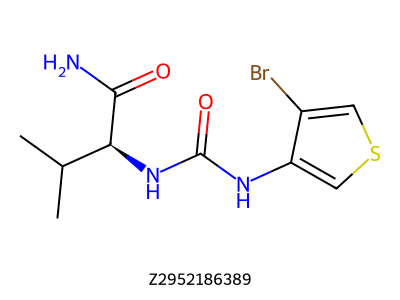

Adduct: [M+H]+


In [131]:
spectrum = random_ms2_with_ms3()  # Optional: seed=42
spectrum = possible[1]
spectrum.plot_root()
print(f"Adduct: {spectrum.metadata['adduct']}")

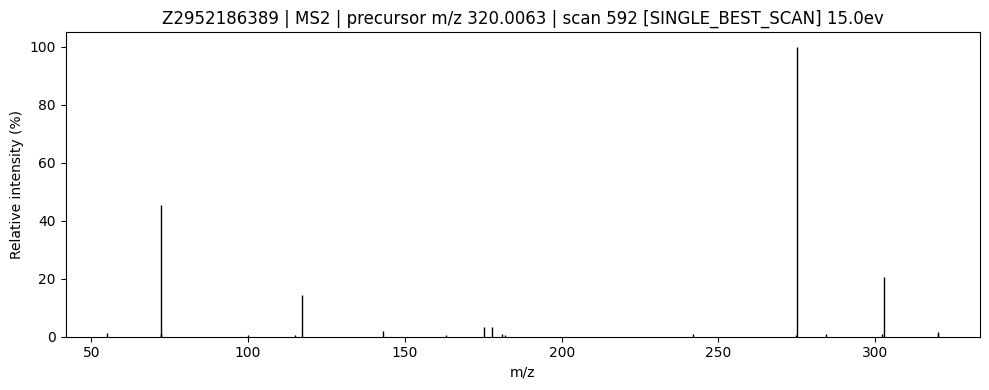

In [132]:
spectrum.plot()

In [133]:
bags = get_candidate_bags(spectrum)
filtered_bags = filter_same_formula_bags(bags)
filtered_bags_ms3 = attach_ms3_spectra(spectrum, filtered_bags)

In [134]:
plot_fragment_bags(filtered_bags[0])
print(len(filtered_bags))

12


In [135]:
predicted_spectra = predict_candidate_bags(model, filtered_bags, collision_energy=40)

/var/folders/lt/z226687j1sn89f7f6xjnz5100000gn/T/ipykernel_75926/4248766172.py:1: RuntimeWarning: bag 8, candidate 0 (candidate_183609499c90773a35e17439025181e846309fa8f3ac90781e9f1f847b14cca9, m/z 241.990798): No represented states: no_valid_state_in_declared_domain
  predicted_spectra = predict_candidate_bags(model, filtered_bags, collision_energy=40)
/var/folders/lt/z226687j1sn89f7f6xjnz5100000gn/T/ipykernel_75926/4248766172.py:1: RuntimeWarning: bag 8, candidate 1 (candidate_83a1aecbc9400a7e1e4c5abb58b369217dcdd7836c87cd6cf5fec35492f0c7df, m/z 241.990798): No represented states: no_valid_state_in_declared_domain
  predicted_spectra = predict_candidate_bags(model, filtered_bags, collision_energy=40)


In [136]:
plot_fragments_with_spectra(
    filtered_bags, predicted_spectra,
    ms3_collision_energies=[60],  # Empty means all available energies.
    only_with_ms3=True,       # True requires MS3 after the energy filter.
    fit_mixture=True,
    color_matches=False,
    strict = 20,
    mirror = True,
)

/Users/islam/Desktop/MS_Pred_Research/MAGMA_Research/distilled_fragdata/src/spectra/mixture.py:110: RuntimeWarning: divide by zero encountered in matmul
  mixed = matrix @ coefficients
/Users/islam/Desktop/MS_Pred_Research/MAGMA_Research/distilled_fragdata/src/spectra/mixture.py:110: RuntimeWarning: overflow encountered in matmul
  mixed = matrix @ coefficients
/Users/islam/Desktop/MS_Pred_Research/MAGMA_Research/distilled_fragdata/src/spectra/mixture.py:110: RuntimeWarning: invalid value encountered in matmul
  mixed = matrix @ coefficients
